# 📦 DataCo Supply Chain Risk Analysis: EDA & Leakage Inspection
**Author:** Person B (@aakritishakya9) & Person A  
**Environment:** Google Colab  
**Objective:** Inspect distributions, check target balance (`Late_delivery_risk`), eliminate feature leakage, and prepare priors for Gaussian Naive Bayes & Logistic Regression.

## 1. Setup & Download Data in Colab (Direct Cloud Download)
Run the cell below. It downloads the DataCo dataset **directly to Google Colab's cloud servers** (nothing is downloaded to your laptop!).

In [8]:
!mkdir -p ./data_raw
!wget -q --show-progress -O ./data_raw/DataCoSupplyChainDataset.csv "https://huggingface.co/idoyaaran/dataco-supply-chain-model/resolve/main/DataCoSupplyChainDataset.csv"
print("✅ Download complete! The 180,000-row dataset is ready inside Colab.")

./data_raw/DataCoSu 100%[===================>]  91.47M  71.4MB/s    in 1.3s    
✅ Download complete! The 180,000-row dataset is ready inside Colab.


## 2. Load and Inspect Dataset

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot styles
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the dataset with latin-1 encoding
df = pd.read_csv('./data_raw/DataCoSupplyChainDataset.csv', encoding='latin-1')
print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 180,519 rows, 53 columns


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


## 3. Target Variable Analysis: `Late_delivery_risk`
Let's inspect the target class balance. Is there class imbalance?

Target Distribution (%):
Late_delivery_risk
1    54.829132
0    45.170868
Name: proportion, dtype: float64


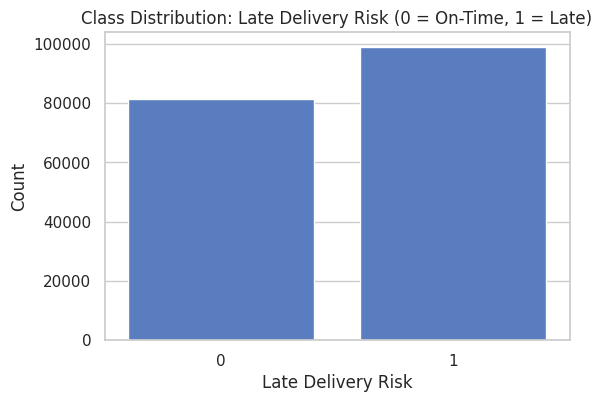


Calculated Priors for Gaussian Naive Bayes:
P(Y=0) On-Time: 0.4517
P(Y=1) Late:    0.5483


In [10]:
target_counts = df['Late_delivery_risk'].value_counts(normalize=True) * 100
print("Target Distribution (%):")
print(target_counts)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Late_delivery_risk')
plt.title("Class Distribution: Late Delivery Risk (0 = On-Time, 1 = Late)")
plt.xlabel("Late Delivery Risk")
plt.ylabel("Count")
plt.show()

# Store priors for Gaussian Naive Bayes
prior_0 = (df['Late_delivery_risk'] == 0).mean()
prior_1 = (df['Late_delivery_risk'] == 1).mean()
print(f"\nCalculated Priors for Gaussian Naive Bayes:")
print(f"P(Y=0) On-Time: {prior_0:.4f}")
print(f"P(Y=1) Late:    {prior_1:.4f}")

## 4. Target Leakage Verification ⚠️
Notice that `Days for shipping (real)` and `Delivery Status` reflect the outcome *after* shipment. Including them would allow the model to cheat and achieve 100% artificial accuracy.

In [11]:
# Inspect relationship between scheduled shipping days and real shipping days
print("Comparing Delivery Status vs Late_delivery_risk:")
print(pd.crosstab(df['Delivery Status'], df['Late_delivery_risk']))

# Notice that 'Late delivery' status directly maps to risk = 1! We MUST exclude it from features.

Comparing Delivery Status vs Late_delivery_risk:
Late_delivery_risk      0      1
Delivery Status                 
Advance shipping    41592      0
Late delivery           0  98977
Shipping canceled    7754      0
Shipping on time    32196      0


## 5. Feature Distributions for Gaussian Naive Bayes
Gaussian Naive Bayes assumes each numerical feature follows a Gaussian (normal) distribution per class. Let's plot the distributions of key order-time features grouped by `Late_delivery_risk`.

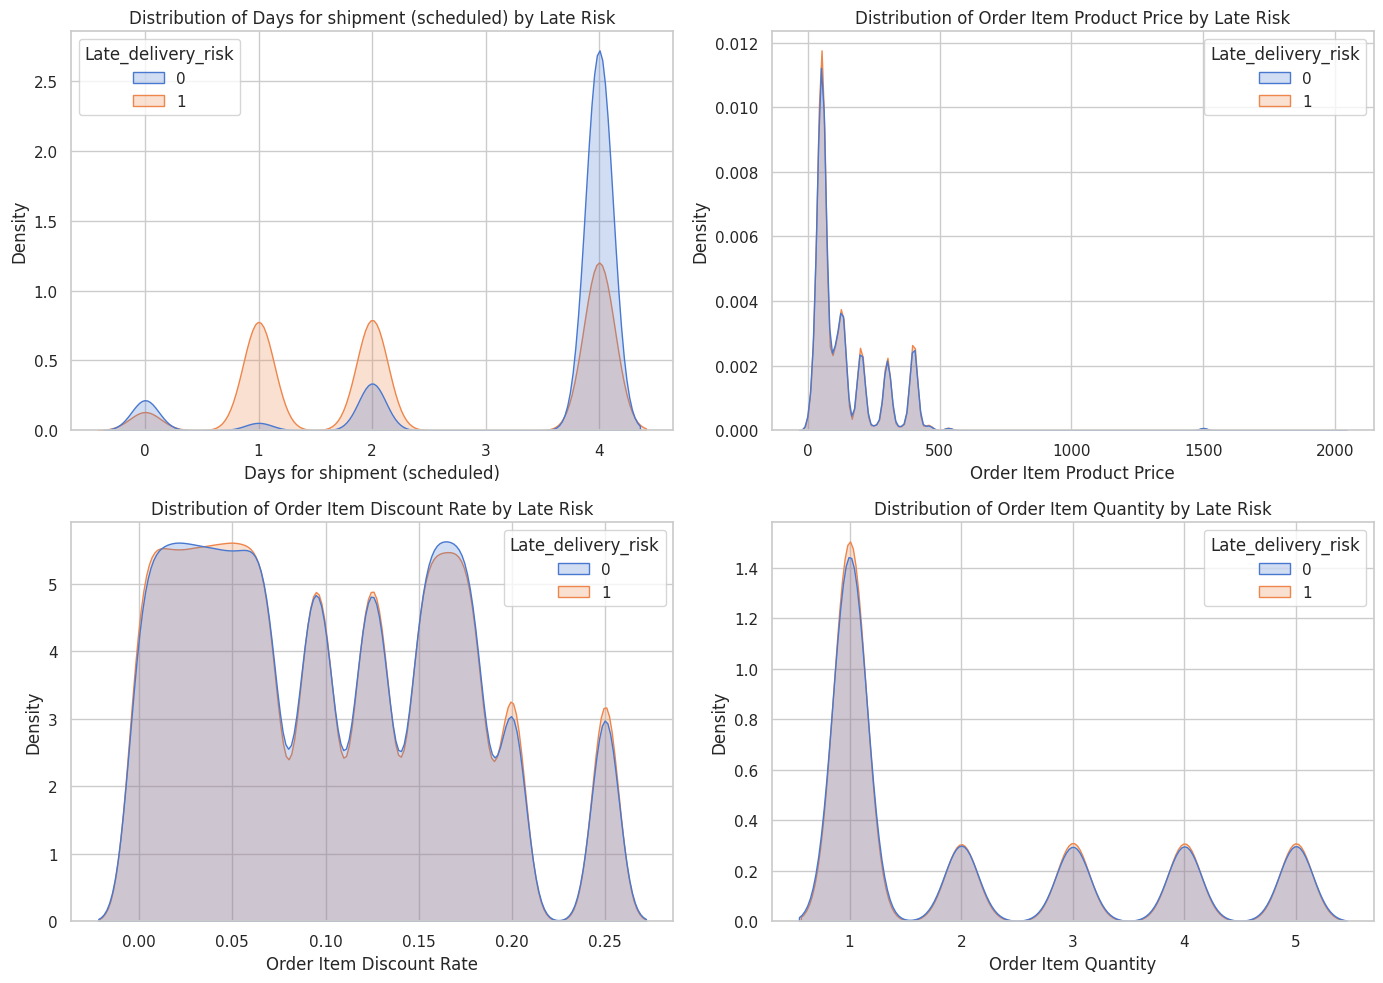

In [12]:
features_to_check = [
    'Days for shipment (scheduled)',
    'Order Item Product Price',
    'Order Item Discount Rate',
    'Order Item Quantity'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, feat in enumerate(features_to_check):
    sns.kdeplot(data=df, x=feat, hue='Late_delivery_risk', common_norm=False, ax=axes[i], fill=True)
    axes[i].set_title(f'Distribution of {feat} by Late Risk')

plt.tight_layout()
plt.show()

## 6. Shipping Mode Impact
Different shipping modes (Standard Class, First Class, Second Class, Same Day) have vastly different delay probabilities.

/tmp/ipykernel_1093/3663605606.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Shipping Mode', y='Late_delivery_risk', ci=None)


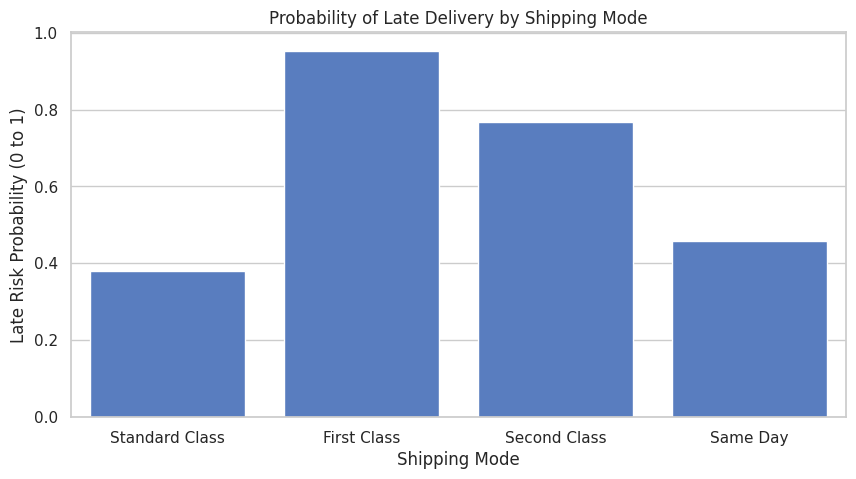

In [13]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='Shipping Mode', y='Late_delivery_risk', ci=None)
plt.title("Probability of Late Delivery by Shipping Mode")
plt.ylabel("Late Risk Probability (0 to 1)")
plt.show()

## 7. Next Steps: Exporting Clean Data & Starting Model Training
Once EDA is finalized in Colab:
1. Save your notebook directly back to GitHub: **File -> Save a copy in GitHub** -> select your repo `supplier-risk-classification`.
2. Person B (@aakritishakya9) starts training `ScratchGaussianNB` on the preprocessed features.
3. Person A tunes gradient descent iterations and learning rate for `ScratchLogisticRegression`.